In [1]:
# pip install nltk, WordCloud, missingno.
import pandas as pd
import numpy as np 

In [2]:
# To access the two dataset 
train = pd.read_csv(r"train.csv")
test = pd.read_csv(r"test.csv")

# 1. >> Data Preprocessing 

In [3]:
train.head()

,id,Time_spent_Alone,Stage_fear,Social_event_attendance,Going_outside,Drained_after_socializing,Friends_circle_size,Post_frequency,Personality
0,0,0.0,No,6.0,4.0,No,15.0,5.0,Extrovert
1,1,1.0,No,7.0,3.0,No,10.0,8.0,Extrovert
2,2,6.0,Yes,1.0,0.0,NaN,3.0,0.0,Introvert
3,3,3.0,No,7.0,3.0,No,11.0,5.0,Extrovert
4,4,1.0,No,4.0,4.0,No,13.0,NaN,Extrovert


In [4]:
# To check for missing values.
train.isnull().sum()

id                              0
Time_spent_Alone             1190
Stage_fear                   1893
Social_event_attendance      1180
Going_outside                1466
Drained_after_socializing    1149
Friends_circle_size          1054
Post_frequency               1264
Personality                     0
dtype: int64

In [5]:
# To drop columns that are irrelevant. 
train.drop(columns = "id", inplace = True)
test.drop(columns = "id", inplace = True)
print("Success.")

Success.


In [6]:
# To check for data type 
train.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 18524 entries, 0 to 18523
Data columns (total 8 columns):
 #   Column                     Non-Null Count  Dtype  
---  ------                     --------------  -----  
 0   Time_spent_Alone           17334 non-null  float64
 1   Stage_fear                 16631 non-null  object 
 2   Social_event_attendance    17344 non-null  float64
 3   Going_outside              17058 non-null  float64
 4   Drained_after_socializing  17375 non-null  object 
 5   Friends_circle_size        17470 non-null  float64
 6   Post_frequency             17260 non-null  float64
 7   Personality                18524 non-null  object 
dtypes: float64(5), object(3)
memory usage: 1.1+ MB


In [7]:
# To Check for duplicated values 
train.duplicated().sum()
train.columns

Index(['Time_spent_Alone', 'Stage_fear', 'Social_event_attendance',
       'Going_outside', 'Drained_after_socializing', 'Friends_circle_size',
       'Post_frequency', 'Personality'],
      dtype='object')

In [8]:
# To check typo error on each column
for col in train:
    print(f"{col}: {train[col].unique()}")

Time_spent_Alone: [ 0.  1.  6.  3.  2.  4. nan  5.  9. 10.  7.  8. 11.]
Stage_fear: ['No' 'Yes' nan]
Social_event_attendance: [ 6.  7.  1.  4.  8.  2.  5. nan  0.  9.  3. 10.]
Going_outside: [ 4.  3.  0.  5. nan  1.  6.  2.  7.]
Drained_after_socializing: ['No' nan 'Yes']
Friends_circle_size: [15. 10.  3. 11. 13. nan  4.  0. 14.  5.  9. 12.  8.  2.  1.  6.  7.]
Post_frequency: [ 5.  8.  0. nan  3.  4.  2.  9. 10.  6.  7.  1.]
Personality: ['Extrovert' 'Introvert']


In [9]:
for col in test:
    print(f"{col}: {train[col].unique()}")

Time_spent_Alone: [ 0.  1.  6.  3.  2.  4. nan  5.  9. 10.  7.  8. 11.]
Stage_fear: ['No' 'Yes' nan]
Social_event_attendance: [ 6.  7.  1.  4.  8.  2.  5. nan  0.  9.  3. 10.]
Going_outside: [ 4.  3.  0.  5. nan  1.  6.  2.  7.]
Drained_after_socializing: ['No' nan 'Yes']
Friends_circle_size: [15. 10.  3. 11. 13. nan  4.  0. 14.  5.  9. 12.  8.  2.  1.  6.  7.]
Post_frequency: [ 5.  8.  0. nan  3.  4.  2.  9. 10.  6.  7.  1.]


In [10]:
# To clean the missing values 
from sklearn.impute import SimpleImputer 

# To seperate the Column into Catergorical and Numerical columns 
cat_col = train.select_dtypes(include = ["object"])
num_col = train.select_dtypes(include = ["float", "int"])

# To get the imputers for Numerical and Catergorical
imp_cat = SimpleImputer(strategy = "most_frequent")
imp_num = SimpleImputer(strategy = "mean")

imputer_cal = imp_cat.fit_transform(cat_col)
imputer_num = imp_cat.fit_transform(num_col)

# To make them as Dataframe 
df_cat = pd.DataFrame(imputer_cal, columns = cat_col.columns)
df_num = pd.DataFrame(imputer_num, columns = num_col.columns)

# To concatenate the two DataFrame as one 
sample = pd.concat([df_cat, df_num], axis = 1)

In [11]:
# To clean the missing values 
# To seperate the Column into Catergorical and Numerical columns 
cat_col1 = test.select_dtypes(include = ["object"])
num_col1 = test.select_dtypes(include = ["float", "int"])

imputer_cal1 = imp_cat.fit_transform(cat_col1)
imputer_num1 = imp_cat.fit_transform(num_col1)

# To make them as Dataframe 
df_cat1 = pd.DataFrame(imputer_cal1, columns = cat_col1.columns)
df_num1 = pd.DataFrame(imputer_num1, columns = num_col1.columns)

# To concatenate the two DataFrame as one 
sample1 = pd.concat([df_cat1, df_num1], axis = 1)

# 2. >> Encoding 

In [12]:
# To convert Categorical Column on the train sample.
from sklearn.preprocessing import LabelEncoder
LE = LabelEncoder()
for column in cat_col:
    sample[column] = LE.fit_transform(sample[column])

In [13]:
# To convert Categorical Column on the test sample.
for column1 in cat_col1:
    sample1[column1] = LE.fit_transform(sample1[column1])

# 3. >> Data Splitting

In [15]:
from sklearn.model_selection import train_test_split
x = sample.drop(columns = "Personality")
y = sample['Personality']

x_train, x_val, y_train, y_val = train_test_split(x, y, test_size= 0.2, random_state= 42, stratify = y)

In [16]:
# To select all the Algorithmns
# pip install xgboost 
from sklearn.ensemble import RandomForestClassifier, AdaBoostClassifier, GradientBoostingClassifier
from sklearn.svm import SVC
from xgboost import XGBClassifier

from sklearn.metrics import confusion_matrix, classification_report, accuracy_score

Models = {"Randforest":RandomForestClassifier(random_state= 42), "AdaBoost":AdaBoostClassifier(random_state= 42), "Gradient":GradientBoostingClassifier(random_state= 42), "SVC":SVC(random_state= 42), "XGBoost":XGBClassifier()}


In [ ]:
# To train and Evaluate the Performance of these models
import matplotlib.pyplot as plt 
import seaborn as sns 
for Names, Model in Models.items():
    Model.fit(x_train, y_train)
    
    # To predict the Personalities
    y_pred = Model.predict(x_val)
    
    # To Evaluate the Performance
    accuracy = accuracy_score(y_val, y_pred)
    classification = classification_report(y_val, y_pred)
    
    # To be visualize in form of a Diagram.
    cm = confusion_matrix(y_val, y_pred)
    
    print("\n"+ ("=" * 40))
    print(f"Model Name:{Names}")
    print(f"Accuracy Score: {accuracy:.0%}")
    print(classification)
    
    plt.style.use("ggplot")
    plt.figure(figsize=(10, 5))
    sns.heatmap(cm, annot = True, fmt = "d", cmap = "coolwarm")
    plt.title(f"Performance of {Names} model")

In [ ]:
# To check for class imbalance. 
import seaborn as sns
plt.figure(figsize = (10, 5))
sns.countplot(x = sample['Personality'])
plt.title("Class Imbalance")
plt.show()

In [ ]:
# To know the values count 
sample['Personality'].value_counts()

In [19]:
from sklearn.utils import resample
df_0 = sample[sample['Personality'] == 0]
df_1 = sample[sample["Personality"] == 1]

# To resample the values. 
samp_df = resample(df_1, replace= True, n_samples= len(df_0))

Personality = pd.concat([df_0, samp_df])

sample = Personality.sample(frac = 1, ignore_index = True)

In [20]:
# Traning and evaluate the Model again after handling class imbalance 
from sklearn.model_selection import train_test_split
x1 = sample.drop(columns = "Personality")
y1 = sample["Personality"]

x1_train, x1_val, y1_train, y1_val = train_test_split(x1, y1, test_size = 0.2, random_state= 42)

In [ ]:
for Names, Model in Models.items():
    Model.fit(x1_train, y1_train)
    
    # To predict the Personalities
    y1_pred = Model.predict(x1_val)
    
    # To Evaluate the Performance
    accuracy = accuracy_score(y1_val, y1_pred)
    classification = classification_report(y1_val, y1_pred)
    
    # To be visualize in form of a Diagram.
    cm = confusion_matrix(y1_val, y1_pred)
    
    print("\n"+ "=" * 40)
    print(f"Model Name:{Names}")
    print(f"Accuracy Score: {accuracy:.0%}")
    print(classification)
    
    plt.style.use("ggplot")
    plt.figure(figsize=(10, 5))
    sns.heatmap(cm, annot = True, fmt = "d", cmap = "coolwarm")
    plt.title(f"Performance of {Names} model")

In [ ]:
for Names, Model in Models.items():
    
    # To predict the Personalities
    Prediction = Model.predict(sample1)
    
    # To present the actual score.
  
    
    # To Evaluate the Performance
    accuracy = accuracy_score(y[:6175], Prediction)
    classification = classification_report(y[:6175], Prediction)
    
    # To be visualize in form of a Diagram.
    cm = confusion_matrix(y[:6175], Prediction)
    
    print("\n"+ "=" * 40)
    print(f"Model Name:{Names}")
    print(f"Accuracy Score: {accuracy:.0%}")
    print(classification)
    
    plt.style.use("ggplot")
    plt.figure(figsize=(10, 5))
    sns.heatmap(cm, annot = True, fmt = "d", cmap = "coolwarm")
    plt.title(f"Performance of {Names} model")

In [24]:
for Name, Model in Models.items():
    print("Names:", Names, "Model:", Model)

Names: XGBoost Model: RandomForestClassifier(random_state=42)
Names: XGBoost Model: AdaBoostClassifier(random_state=42)
Names: XGBoost Model: GradientBoostingClassifier(random_state=42)
Names: XGBoost Model: SVC(random_state=42)
Names: XGBoost Model: XGBClassifier(base_score=None, booster=None, callbacks=None,
              colsample_bylevel=None, colsample_bynode=None,
              colsample_bytree=None, device=None, early_stopping_rounds=None,
              enable_categorical=False, eval_metric=None, feature_types=None,
              feature_weights=None, gamma=None, grow_policy=None,
              importance_type=None, interaction_constraints=None,
              learning_rate=None, max_bin=None, max_cat_threshold=None,
              max_cat_to_onehot=None, max_delta_step=None, max_depth=None,
              max_leaves=None, min_child_weight=None, missing=nan,
              monotone_constraints=None, multi_strategy=None, n_estimators=None,
              n_jobs=None, num_parallel_tree

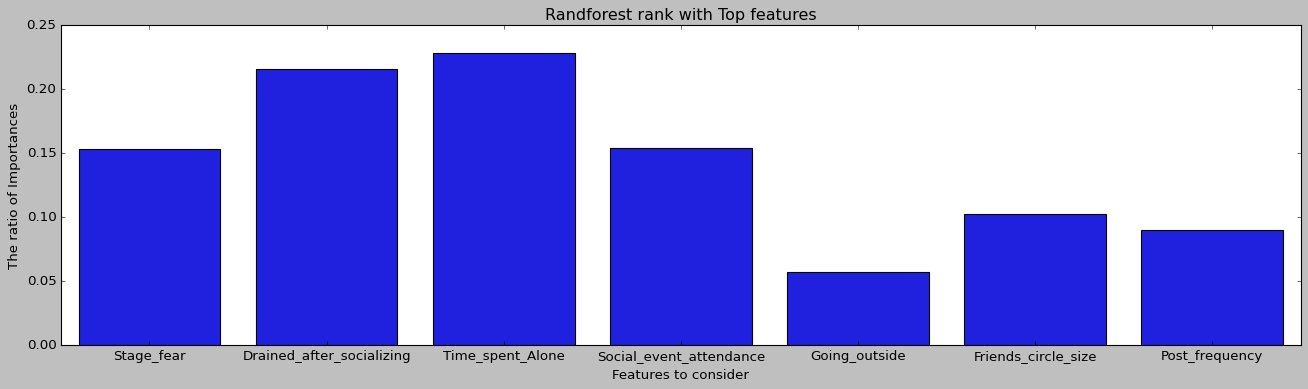

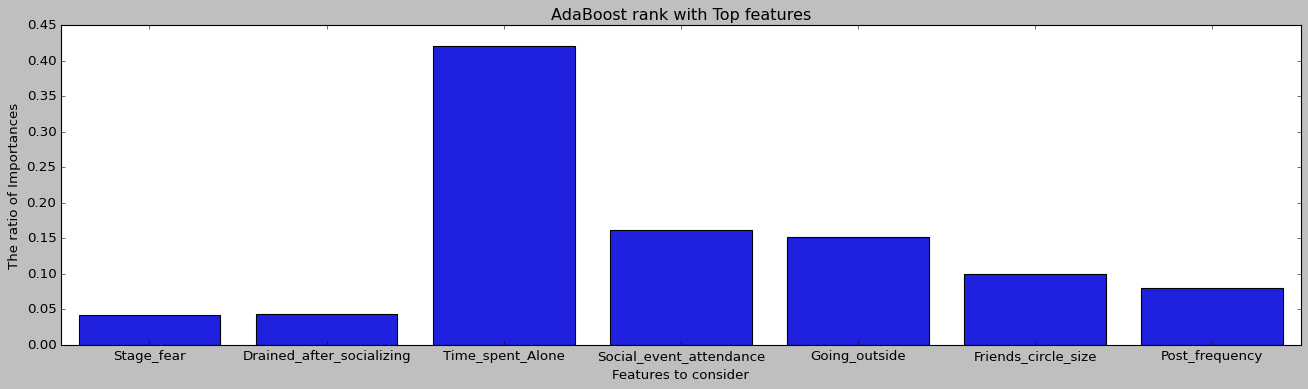

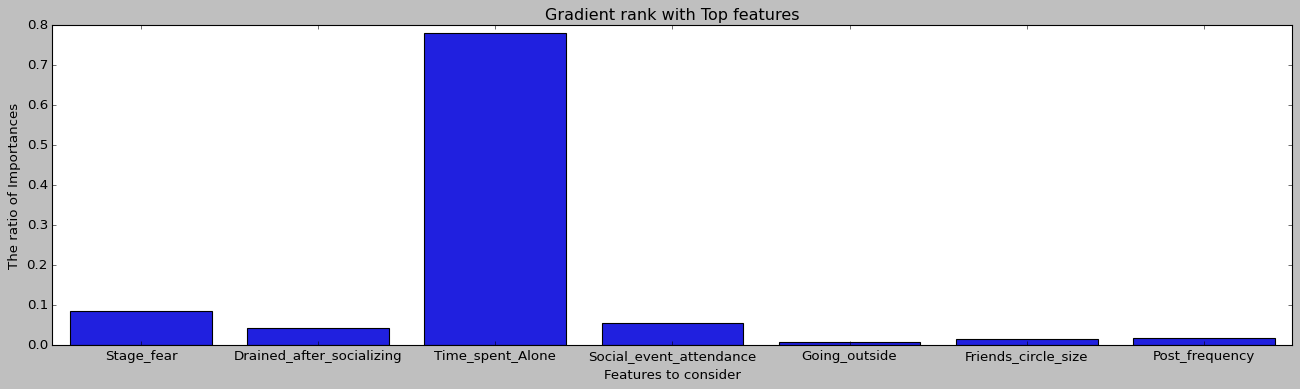

Error Message:'SVC' object has no attribute 'feature_importances_'


<Figure size 1600x400 with 0 Axes>

In [47]:
# To Visualize the Features will the highest correlation to the Target variable. 
try:
    for Names, Model in Models.items():
        plt.style.use("fast")
        plt.figure(figsize = (20, 5))
        sns.barplot(x = x.columns, y = Model.feature_importances_)
        plt.title(f"{Names} rank with Top features")
        plt.xlabel("Features to consider")
        plt.ylabel("The ratio of Importances")
        plt.show()
except Exception as e:
    print(f"Error Message:{e}")

In [ ]:
# To save a model.
import joblib as jb 
jb.dump( Models['Randforest'], "Personality_model.pki",)

['Personality_model.pki']